In [10]:
import os
import numpy as np 
from astropy.io import fits 
from glob import glob 
import matplotlib.pyplot as plt


main_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/'

science_filepaths = glob(main_dir + 'SCIENCE_FLAT_CORR_SPHER*.fits')
flux_filepaths = glob(main_dir + 'FLUX_FLAT_CORR_SPHER*.fits')
star_center_filepaths = glob(main_dir + 'STAR_CENTER_FLAT_CORR_SPHER*.fits')


star_center_filepaths.sort()
science_filepaths.sort()
flux_filepaths.sort()


print("science")
for science in science_filepaths:
    hdul = fits.open(science)
    print (hdul[0].header['ESO INS1 FILT NAME'],  hdul[0].data.shape, os.path.basename(science))
    hdul.close()

print("flux")
for flux in flux_filepaths:
    hdul = fits.open(flux)
    print (hdul[0].header['ESO INS1 FILT NAME'],  hdul[0].data.shape)
    hdul.close()
    
print("star_center")
for star_center in star_center_filepaths:   
    hdul = fits.open(star_center)
    print (hdul[0].header['ESO INS1 FILT NAME'],  hdul[0].data.shape, os.path.basename(star_center))
    hdul.close()

science
flux
star_center


In [50]:
hdul = fits.open(science_filepaths[0])
header  = hdul[0].header
for h in header:
    if isinstance(header[h], str):
        if 'SPHER' in header[h]:
            print(h, hdul[0].header[h])

header

INSTRUME SPHERE
ORIGFILE SPHERE_IRDIFS_IRDIS_OBS205_0099.fits
ESO INS4 DID1 SPHERE_ICS-374390
ESO INS4 ID SPHERE/176642
ESO OCS DET1 IMGNAME SPHERE_IRDIFS_IRDIS_OBS
ESO TPL ID SPHERE_irdifs_obs
ESO TPL PRESEQ SPHERE_irdifs_obs.seq
ARCFILE SPHER.2023-07-24T07:44:57.369.fits
DARKFILE DARK_SPHER.2023-07-24T13:44:01.063.fits


SIMPLE  =                    T / Standard FITS                                  
BITPIX  =                  -64 / # of bits per pix value                        
NAXIS   =                    3 / # of axes in data array                        
NAXIS1  =                 2048 / # of pixels in axis1                           
NAXIS2  =                 1024 / # of pixels in axis2                           
NAXIS3  =                   18 / # of pixels in axis3                           
EXTEND  =                    T / FITS Extension may be present                  
BZERO   =                  0.0 / Pixel=FITS*BSCALE+BZERO                        
BSCALE  =                  1.0 / Pixel=FITS*BSCALE+BZERO                        
ORIGIN  = 'ESO-PARANAL'        / European Southern Observatory                  
DATE    = '2023-07-24T07:47:38.3921' / Date the file was written                
TELESCOP= 'ESO-VLT-U3'         / ESO <TEL>                                      
INSTRUME= 'SPHERE  '        

In [ ]:
file_creation_time = 2023-07-24T07:47:38.3921

sequencer_start_time = 2023-07-24T07:44:57.3687 #HIERARCH ESO DET SEQ UTC

sequencer_exp_time = 160.80561  #HIERARCH ESO DET SEQ1 EXPTIME 


HIERARCH ESO DET DITDELAY = 0.1 / [s] Delay before integration 



In [39]:
hdul[0].data.shape

(18, 1024, 2048)

In [ ]:
18 * 8 

144

In [ ]:
2.5 * np.log10(  )

-3.745572285252232

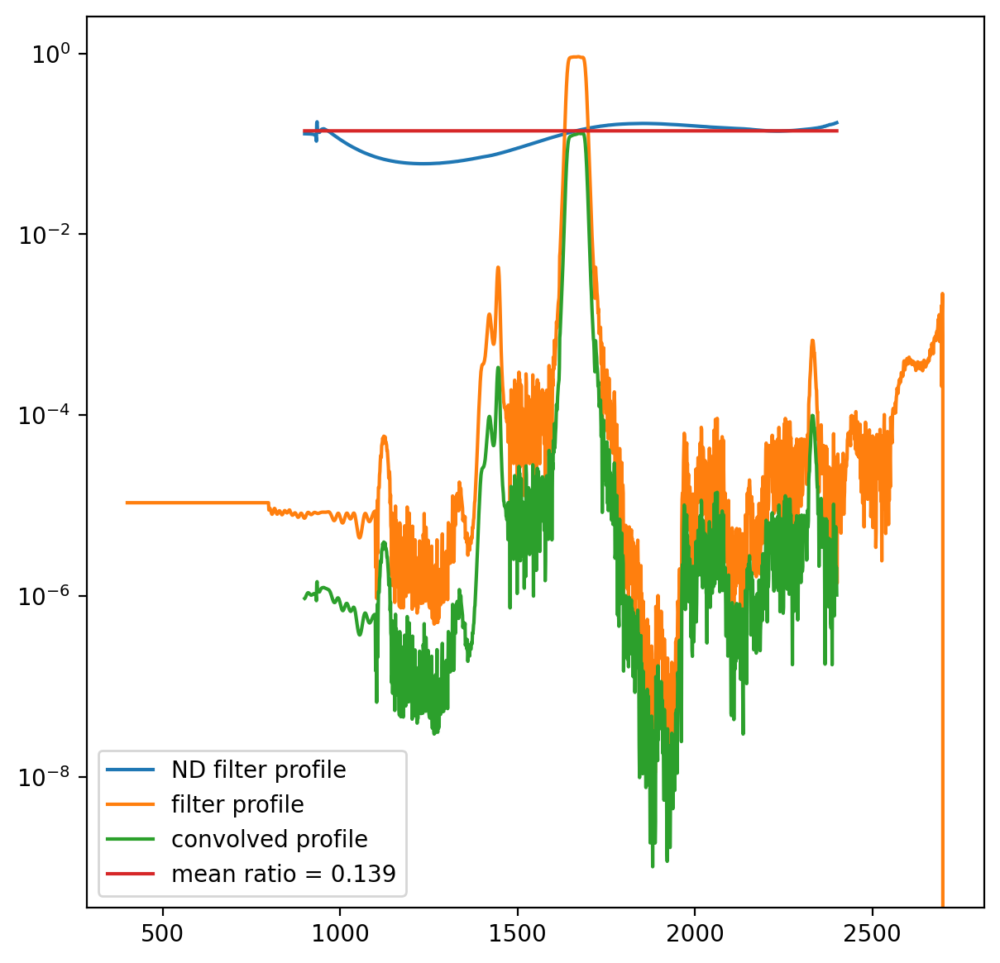

0.13935443328974143

In [16]:
import pandas as pd 
from scipy.integrate import quad
import numpy as np

def get_ratio_for_nd_filter(wave_filter, nd_filter, L_or_R, plot = False):

    if 'DB' in wave_filter:
        wave_filter = wave_filter.replace('DB', 'D')

    # get transmittsion profile
    trans_profile_file = '/home/pasteimle/code/IRDIS_FILTERS/SPHERE_IRDIS_' + wave_filter + '.dat'


    if np.loadtxt(trans_profile_file).transpose().shape[0] == 3:
        trans_wave, trans1, trans2 = np.loadtxt(trans_profile_file).transpose()
        if L_or_R == 'LEFT':
            trans = trans1
        elif L_or_R == 'RIGHT':
            trans = trans2
        else:
            raise ValueError()

    elif np.loadtxt(trans_profile_file).transpose().shape[0] == 2:
        trans_wave, trans = np.loadtxt(trans_profile_file).transpose()

    # get the ndfilter:
    nd_file = '/home/pasteimle/code/IRDIS_FILTERS/SPHERE_CPI_ND.dat'
    ND_DF = pd.DataFrame(np.loadtxt(nd_file), columns=['wavelength', 'ND0.0','ND1.0','ND2.0','ND3.5'])

    nd_wave = ND_DF['wavelength'].values
    nd_trans = ND_DF['ND' + nd_filter.split('_')[-1]].values




    nd_wave_start, nd_wave_stop = np.min(nd_wave), np.max(nd_wave)

    start = max(nd_wave.min(), trans_wave.min())
    end = min(nd_wave.max(), trans_wave.max())

    # Create masks
    mask_A = (nd_wave >= start) & (nd_wave <= end)
    mask_B = (trans_wave >= start) & (trans_wave <= end)

    # Apply masks
    nd_wave_cut = nd_wave[mask_A]
    nd_trans_cut = nd_trans[mask_A]

    trans_wave_B_cut = trans_wave[mask_B]
    trans_cut = trans[mask_B]

    convoluted_trans = trans_cut * nd_trans_cut


    # as the profile is sampled by 1 Angstrom, the integral is simply the sum of the transmission
    trans_integrate = np.nansum(trans_cut)
    convoluted_trans_integrate = np.nansum(convoluted_trans)

    ratio = convoluted_trans_integrate/trans_integrate

    if plot:
        plt.figure(figsize = (7,7), dpi = 200)
        plt.plot(nd_wave, nd_trans, label = 'ND filter profile')
        plt.plot(trans_wave, trans, label = 'filter profile')
        plt.plot(nd_wave_cut, convoluted_trans, label = 'convolved profile')
        plt.plot(nd_wave_cut, np.ones(len(nd_wave_cut))*ratio, label = 'mean ratio = {:1.3f}'.format(ratio))
        plt.yscale('log')
        plt.legend()
        plt.show()


    return ratio



nd_filter = 'FILT_ND_1.0'
wave_filter = 'DB_H23'

get_ratio_for_nd_filter(wave_filter, nd_filter, 'RIGHT', plot = True)

In [56]:
sat_spots =[(0,0), (0,0), (0,0), (0,0)]

if sat_spots == [(0,0), (0,0), (0,0), (0,0)]:
    print('true')

true


((995, 885), (995, 885))

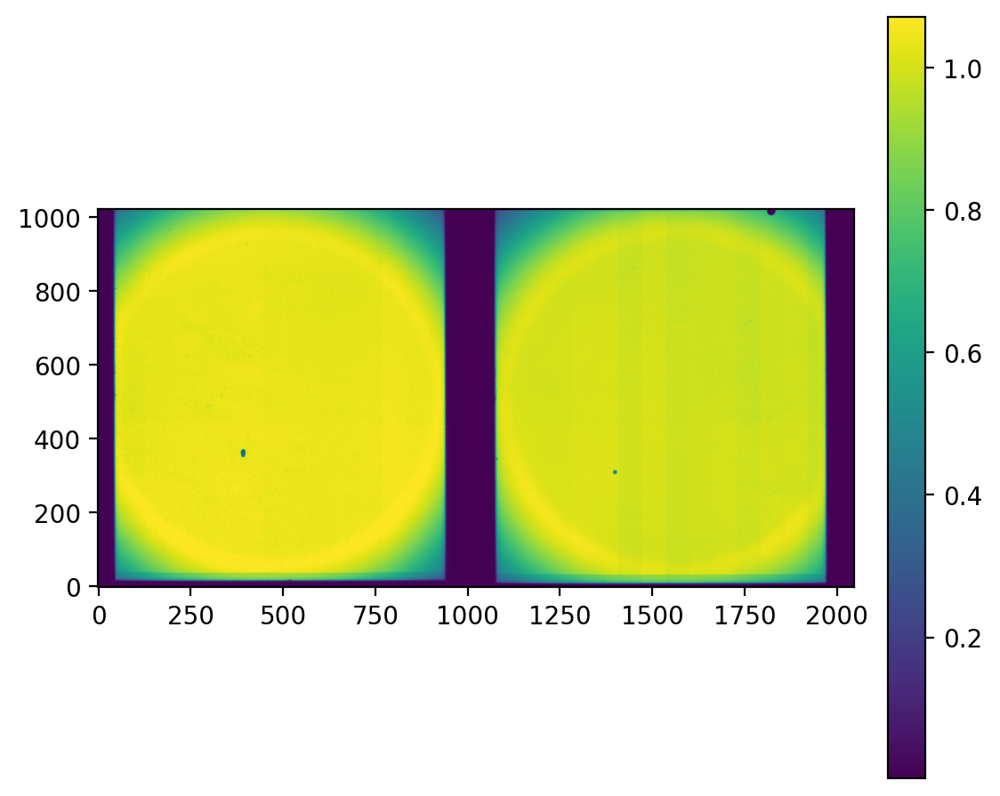

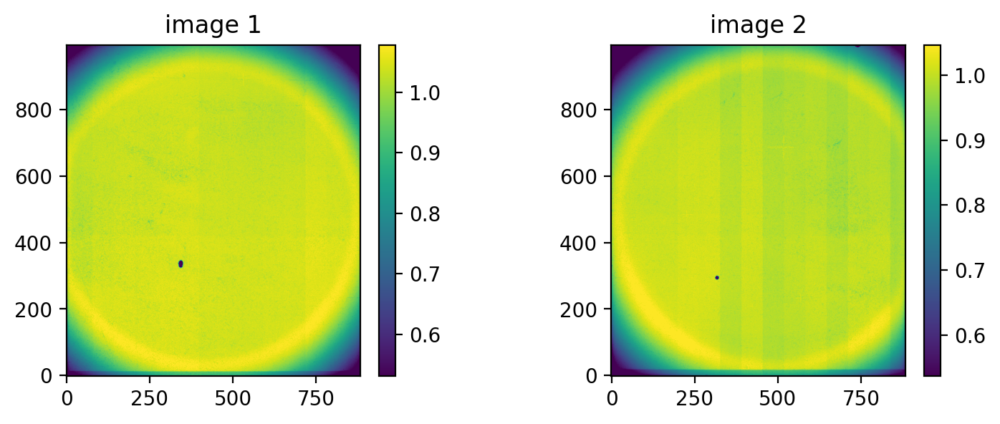

In [54]:
from HCIutils import show_img

main_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/'
master_flat_filepath = main_dir + 'MASTER_FLAT.fits'


data = fits.getdata(master_flat_filepath)

data1 = data[25:1020, 50:935]
data2 = data[15:1010, 1080:1965]



show_img(data)
show_img([data1, data2],)

data1.shape, data2.shape

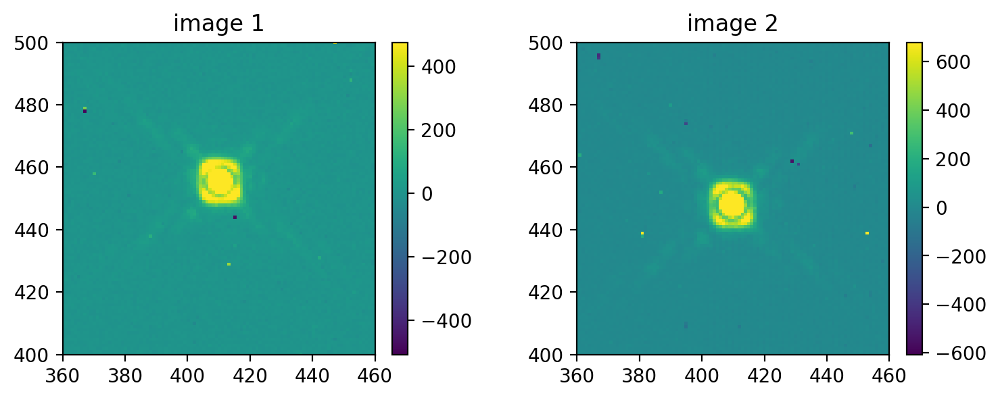

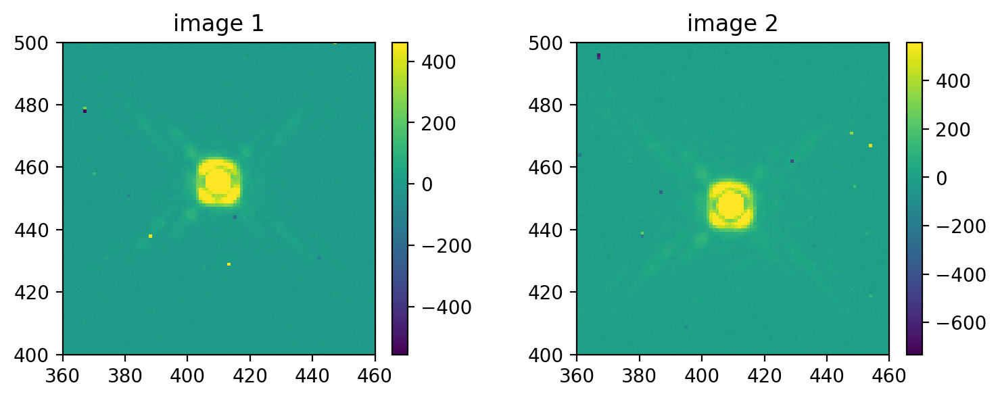

In [5]:
all_flux_left = glob(main_dir + 'FLUX_LEFT*.fits')
all_flux_left.sort()
all_flux_right = glob(main_dir + 'FLUX_RIGHT*.fits')
all_flux_right.sort()

show_img([fits.getdata(all_flux_left[0])[0], fits.getdata(all_flux_right[0])[0]], xlim=(360, 460), ylim=(400, 500), minper=0.1, maxper=99.9)
show_img([fits.getdata(all_flux_left[1])[0], fits.getdata(all_flux_right[1])[0]], xlim=(360, 460), ylim=(400, 500), minper=0.1, maxper=99.9)

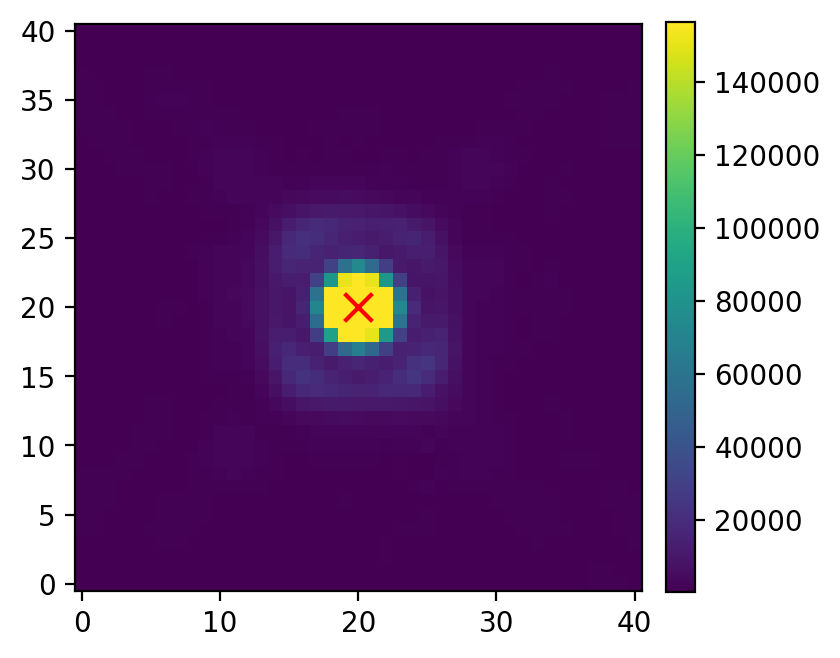

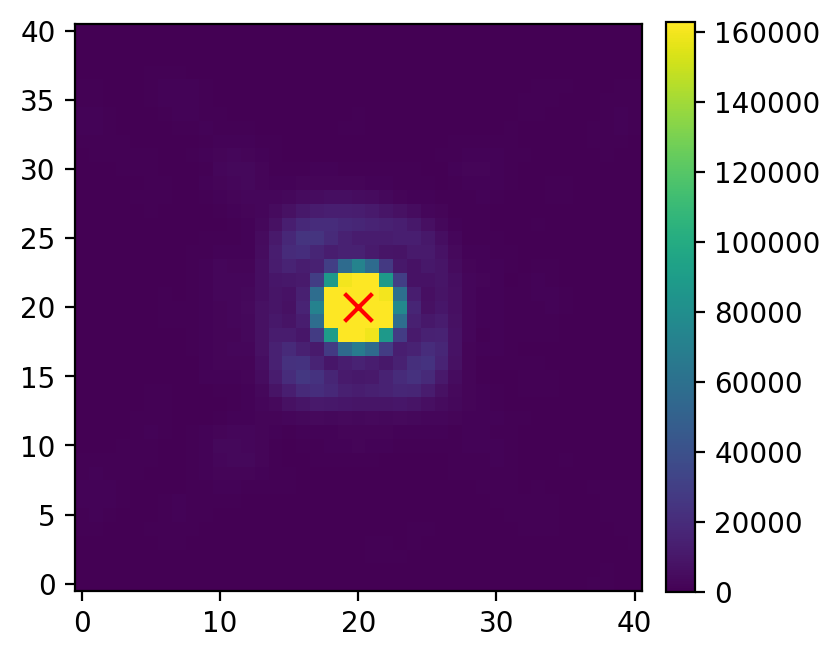

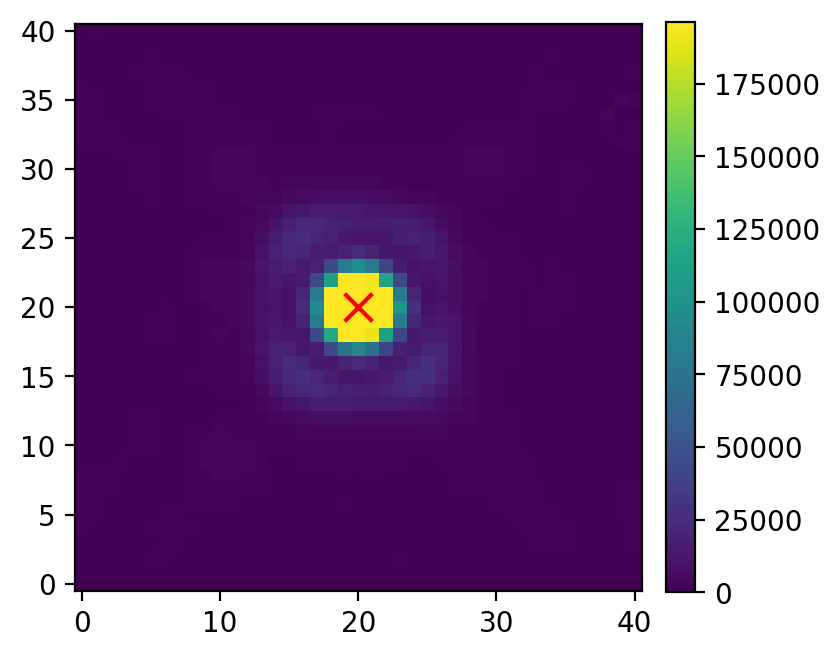

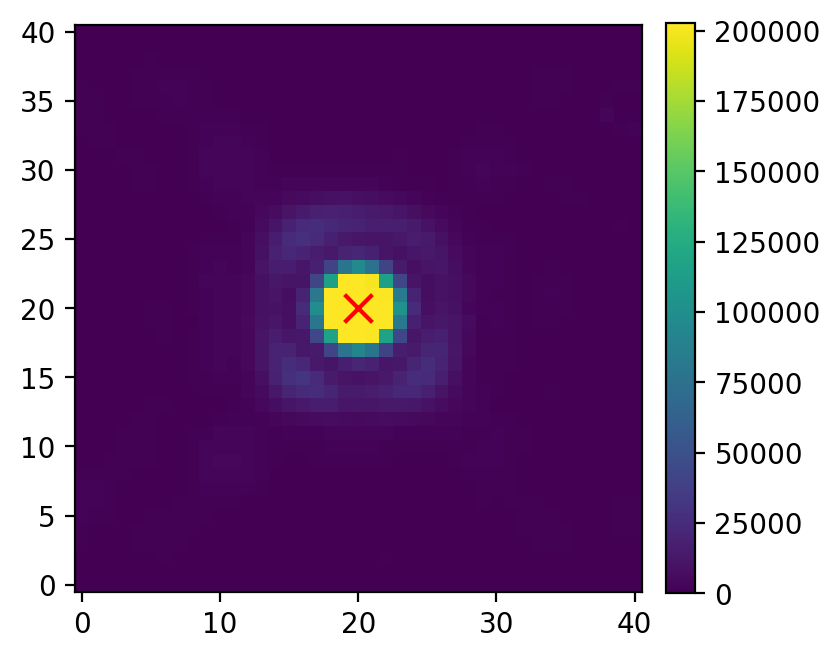

In [6]:
from photutils.centroids import centroid_1dg, centroid_2dg
from vip_hci.var import fit_2dgaussian, frame_center # var is a sub-package with various utility routines
from vip_hci.preproc import frame_shift, cube_shift


 
science_exp_time = 8

def create_flux_file(input_file, center = (360, 400), plot=False):

        hdul = fits.open(input_file)
        data = hdul[0].data[:,50:-50,50:-50]
        header = hdul[0].header
        exp_time = header['EXPTIME']
        nd_filter = header['HIERARCH ESO INS4 FILT2 ID']
        wave_filter = header['ESO INS1 FILT NAME']
        hdul.close()


        # get the ratios by which the flux needs to be rescaled

        # since this is the transmittion profile so smaller than 1 we need to divide by it
        nd_ratio = get_ratio_for_nd_filter(wave_filter, nd_filter)
        
        # and also the exp time ratio
        exp_time_ratio = science_exp_time/exp_time

        # now stack the exposures in a median file toegther to reduce noise
        stacked_flux_image = np.nanmedian(np.nan_to_num(data), axis = 0)

        # fit a gauss to find the center 
        med_y, med_x = fit_2dgaussian(stacked_flux_image, crop=True, cent=center, cropsize=31, threshold=True, sigfactor=4, full_output=False, debug=False)

        #cut out the center of the flux image

        # divide the shift in integer and float
        int_center_x = int(np.floor(med_x))
        int_center_y = int(np.floor(med_y))

        float_center_x = med_x - int_center_x
        float_center_y = med_y - int_center_y

        # first shift the center to a full pixel
        float_centered_image = frame_shift(stacked_flux_image, -float_center_y, -float_center_x, imlib='ndimage-interp', interpolation='biquintic')

        # then cut out 20 pixels around the central one
        int_centered_image = float_centered_image[int_center_y-20:int_center_y+21, int_center_x-20:int_center_x+21]

        # lastly rescale the flux 
        rescaled_image = int_centered_image * exp_time_ratio / nd_ratio 

        # and plot the final image (optional)
        if plot: 
            show_img(rescaled_image, minper=1, maxper=99, size =2)
            plt.scatter(20,20, marker='x', color='red', s=100)
            plt.show()

        # lastly save the flux file 

        hdu_flux = fits.PrimaryHDU(data=rescaled_image)
        hdul_flux = fits.HDUList([hdu_flux])

        header['EXPTIMERATIO'] = exp_time_ratio
        header['ND_RATIO'] = 1/nd_ratio

        hdul_flux[0].header = header
        # hdul_flux.writeto(output_filepath, overwrite=True)
        return rescaled_image


for flux in all_flux_left+all_flux_right:
    
    create_flux_file(flux, plot = True)

   
        

        


SCIENCE_LEFT_SPHER.2023-07-24T07:44:57.369.fits
SCIENCE_LEFT_SPHER.2023-07-24T07:47:47.109.fits
SCIENCE_LEFT_SPHER.2023-07-24T07:50:32.153.fits
SCIENCE_LEFT_SPHER.2023-07-24T07:53:18.209.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:05:40.544.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:08:19.549.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:10:55.535.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:13:32.609.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:25:05.379.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:27:43.892.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:30:20.945.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:32:58.074.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:44:35.091.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:47:12.347.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:49:49.358.fits
SCIENCE_LEFT_SPHER.2023-07-24T08:52:26.365.fits
SCIENCE_LEFT_SPHER.2023-07-24T09:03:57.589.fits
SCIENCE_LEFT_SPHER.2023-07-24T09:06:34.901.fits
SCIENCE_LEFT_SPHER.2023-07-24T09:09:11.799.fits
SCIENCE_LEFT_SPHER.2023-07-24T09:11:47.904.fits
SCIENCE_LEFT_SPHER.2023-07-24T09:23:15.7

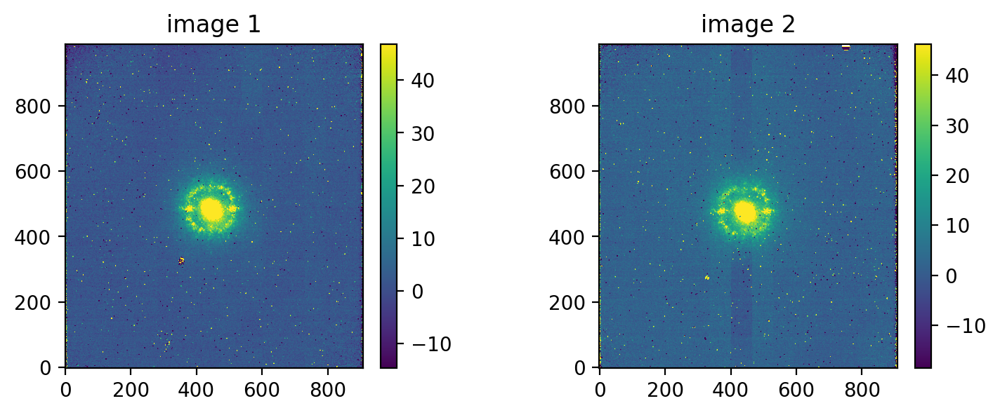

In [7]:
all_science_left = glob(main_dir + 'SCIENCE_LEFT*.fits')
all_science_left.sort()
all_science_right = glob(main_dir + 'SCIENCE_RIGHT*.fits')
all_science_right.sort()

show_img([fits.getdata(all_science_left[0])[0], fits.getdata(all_science_right[0])[0]])


left_cube = []
angs = []
for file in all_science_left: 
    print(os.path.basename(file))
    data = fits.getdata(file)
    angend = fits.getheader(file)['HIERARCH ESO TEL PARANG END']
    angstart = fits.getheader(file)['HIERARCH ESO TEL PARANG START']

    diff = (angstart - angend) / len(data)

    angs_i = np.linspace(angstart + diff/2, angend, len(data))

    for ang, image in zip(angs_i, data): 
        left_cube.append(image)
        angs.append(ang)


angs = np.array(angs)
left_cube = np.array(left_cube)

In [135]:
left_cube.shape
from vip_hci.preproc import cube_recenter_2dfit, cube_recenter_dft_upsampling
from vip_hci.fm import normalize_psf

psf, flux, fwhm_irdis = normalize_psf(np.nan_to_num(left_cube[0]), size=39, debug=False, full_output=True)

cube1, shy1, shx1 = cube_recenter_dft_upsampling(np.nan_to_num(left_cube[::10]), upsample_factor=1, center_fr1=(435, 480), fwhm=fwhm_irdis, subi_size=101, negative=True, full_output=True)


Mean FWHM: 29.272
Flux in 1xFWHM aperture: 186693.847
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-16 13:09:32
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


ValueError: NaN values found, please remove NaNs from your input data or use the `reference_mask`/`moving_mask` keywords, eg: phase_cross_correlation(reference_image, moving_image, reference_mask=~np.isnan(reference_image), moving_mask=~np.isnan(moving_image))

Process ForkPoolWorker-43:
Process ForkPoolWorker-41:
Process ForkPoolWorker-44:
Process ForkPoolWorker-39:
Process ForkPoolWorker-31:
Process ForkPoolWorker-35:
Process ForkPoolWorker-38:
Process ForkPoolWorker-32:
Process ForkPoolWorker-42:
Process ForkPoolWorker-33:
Process ForkPoolWorker-36:
Process ForkPoolWorker-27:
Process ForkPoolWorker-26:
Process ForkPoolWorker-40:
Process ForkPoolWorker-37:
Process ForkPoolWorker-29:
Process ForkPoolWorker-25:
Process ForkPoolWorker-28:
Process ForkPoolWorker-34:
Process ForkPoolWorker-30:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Trace

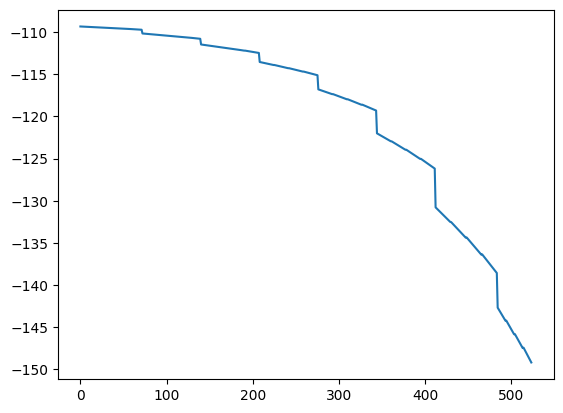

In [127]:
plt.plot(angs)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-16 12:49:36
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Median psf reference subtracted
Done derotating and combining
Running time:  0:01:39.588128
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


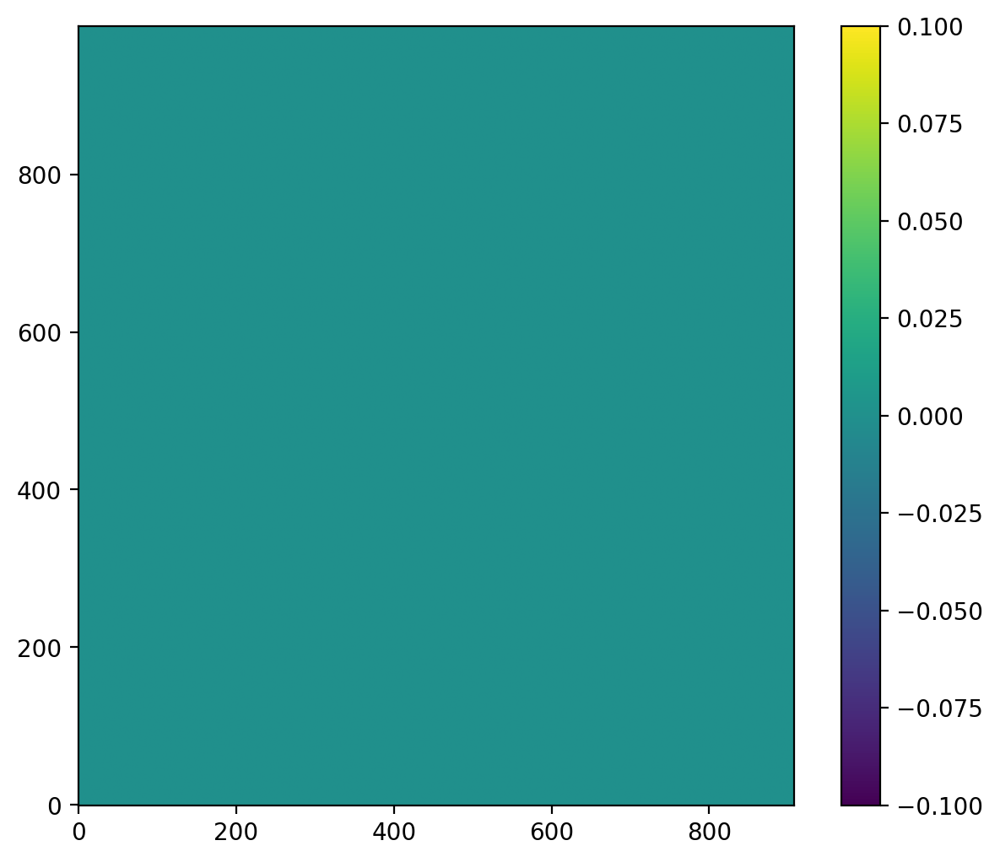

In [131]:
from vip_hci.psfsub import median_sub

imlib = 'vip-fft' # other options: 'opencv', 'skimage'
interpolation=None  

residual = median_sub(np.nan_to_num(cube1), -np.array(angs)[::10], imlib=imlib, interpolation=interpolation, nproc = 12)

show_img(residual)

`Force_odd` is True and frame size is even, therefore new frame size was set to 199


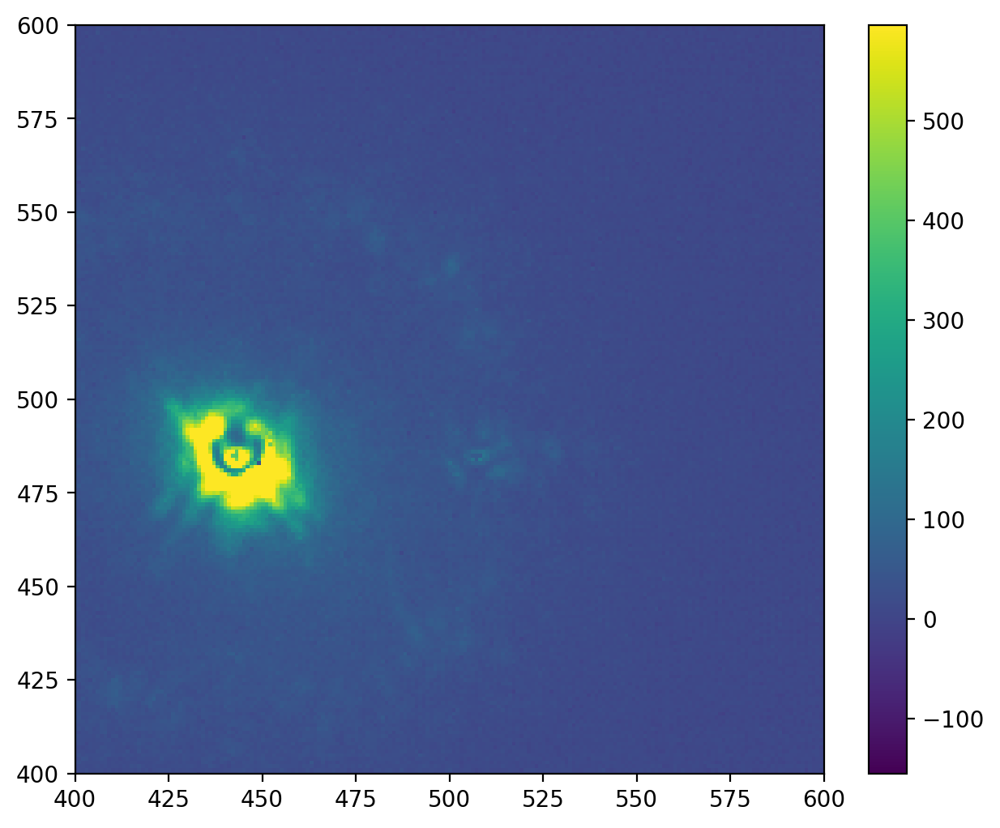

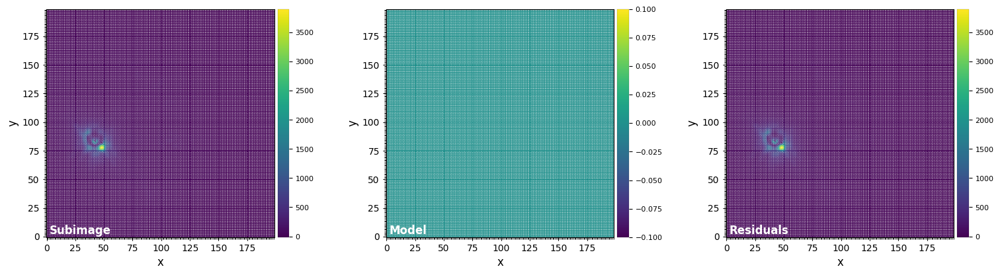

FWHM_y = 2.7680776601369656e-38
FWHM_x = 2.7680776601369656e-38 

centroid y = 86.77926886132308
centroid x = 64.82725883040223
centroid y subim = 86.77926886132308
centroid x subim = 64.82725883040223 

amplitude = 239.1640965344418
theta = -13961.061640380258

Mean FWHM: 0.000
Flux in 1xFWHM aperture: 0.000


In [ ]:
science_image = fits.getdata(all_science_left[10])[10]

science_image[310:350, 330:370] = np.nanmedian(science_image)

show_img(science_image, minper = 0.1, maxper = 99.9, xlim=(400, 600), ylim=(400, 600))
plt.scatter(350,350)
norm_psf, flux, fwhm = normalize_psf(science_image[400:600, 400:600], fwhm='fit', full_output=True, debug=True)

[(390.7106848376716, 498.4392655140138), (460.7106848376716, 498.4392655140138), (390.7106848376716, 428.4392655140138), (460.7106848376716, 428.4392655140138)]


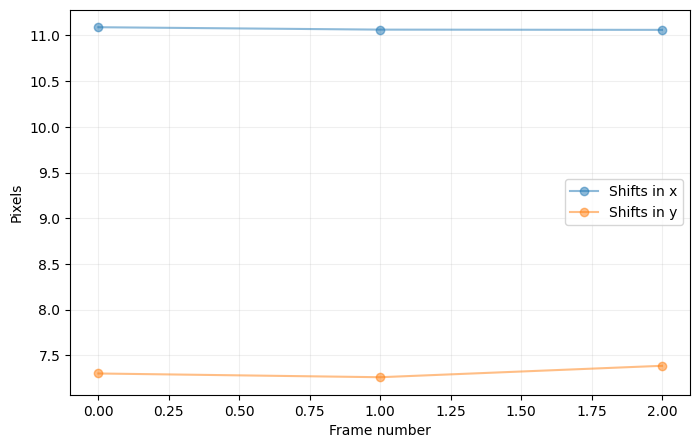

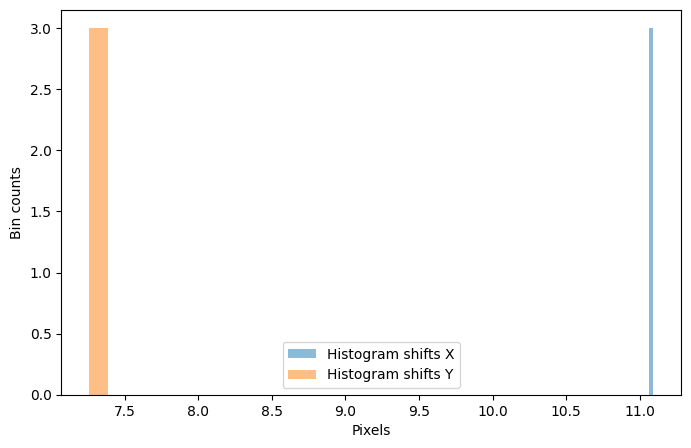

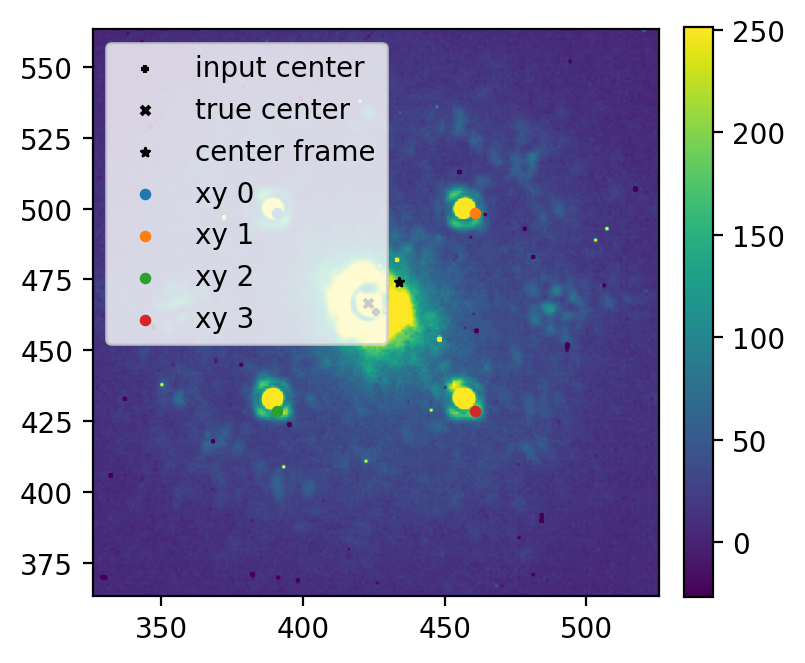

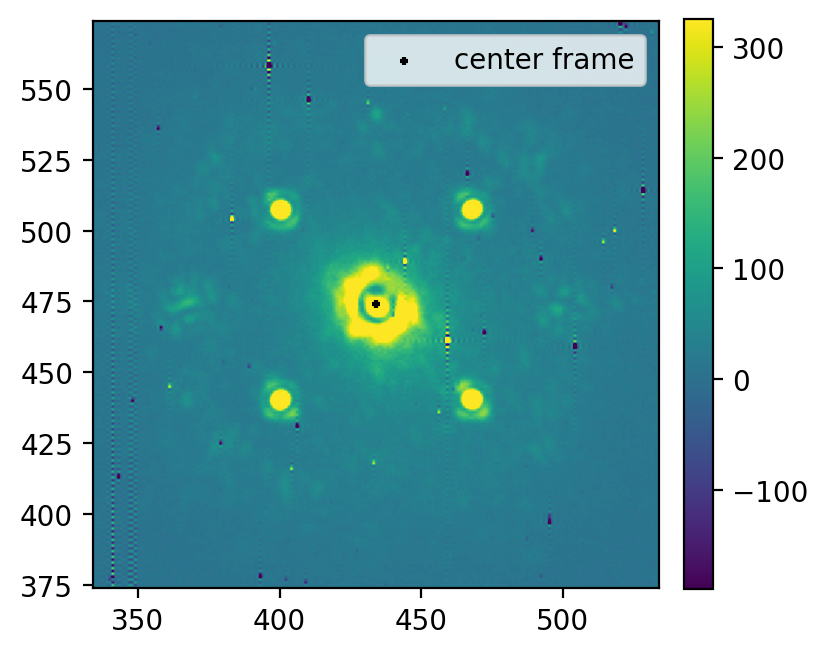

[(395.7106848376716, 493.4392655140138), (455.7106848376716, 493.4392655140138), (395.7106848376716, 433.4392655140138), (455.7106848376716, 433.4392655140138)]


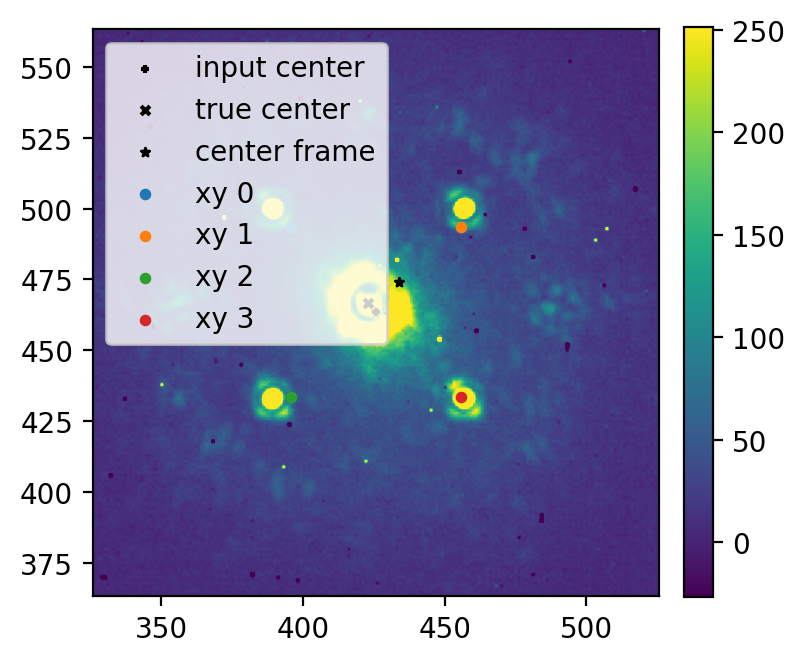

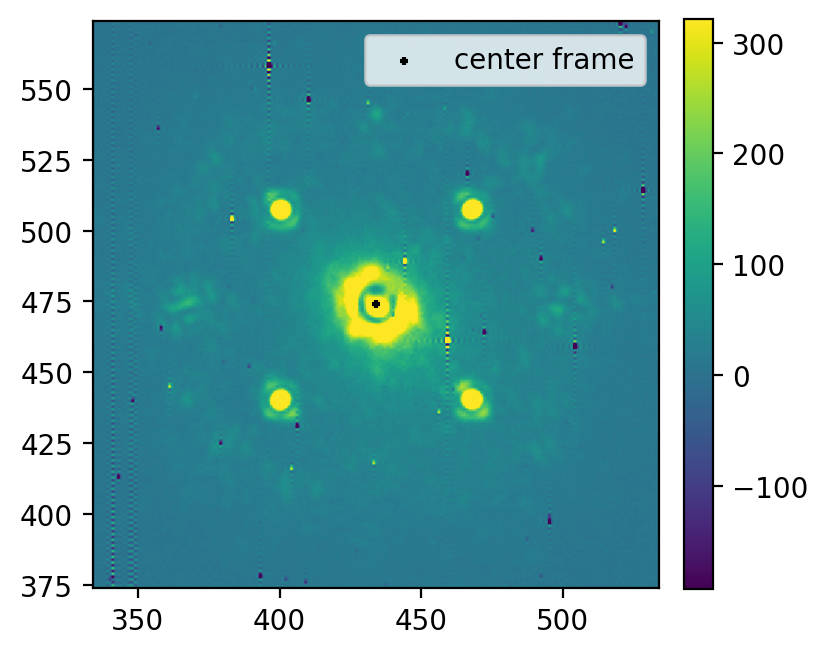

In [37]:
from photutils.centroids import centroid_1dg
from vip_hci.var import frame_center
from vip_hci.preproc import cube_recenter_satspots, frame_center_satspots, cube_recenter_radon
from HCIutils import circular_aperture

all_center_left = glob(main_dir + 'STAR_CENTER_LEFT*.fits')
all_center_right = glob(main_dir + 'STAR_CENTER_RIGHT*.fits')


def get_center_frame(file, center = None, sat_spots = None):

    data = np.nan_to_num(fits.getdata(file))

    data = data[:, 20:-20, 20:-20]

    image = np.nanmedian(data, axis=0)

    # try to find the center using centroid_1dg
    if center is None:
        center = centroid_1dg(image) 

    #then roll the center there
    cy, cx = frame_center(image)
    # shifted_data = np.roll(data, int(cy - center[1]), axis=1)
    # shifted_data = np.roll(shifted_data, int(cx - center[0]), axis=2)

    # and try to use the now centered image with the sattelite spots
    if sat_spots is None:
        sat_spots = np.array([ [-30, 30], [30, 30], [-30,-30], [30, -30]]) + center

        sat_spots_input = [(f[0], f[1]) for f in sat_spots]

    else:
        # if the sat_spots are given, we need to shift them to the center of the image since we cut the image at the start
        sat_spots_input = [(f[0] -20, f[1] -20) for f in sat_spots]

    print(sat_spots_input)

    res = frame_center_satspots(image, xy=sat_spots_input, subi_size=21, verbose=False, debug=False, shift=True, fit_type='gaus')

    shifted_image = res[0]
    shiftxy = (res[1], res[2])


    true_center = (np.mean(res[3]), np.mean(res[4]))


    # the unshifted image 
    show_img(image, minper=0.1, maxper=99.9, xlim=[center[0]-100,center[0]+100], ylim=[center[1]-100,center[1]+100], size = 2)
    plt.scatter(center[0], center[1], color='black', s=10, label='input center', marker = '+')
    plt.scatter(true_center[1], true_center[0], color='black', s=10, label='true center', marker = 'x')
    plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '*')

    for j, xy in enumerate(sat_spots_input):
        plt.scatter(xy[0], xy[1], color=f'C{j}', s=10, label=f'xy {j}')
    plt.legend()
    plt.show()


    # the shifted image with centers
    show_img(shifted_image, minper=0.1, maxper=99.9, xlim=[cx-100,cx+100], ylim=[cy-100,cy+100], size = 2)
    plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '+')

    plt.legend()
    plt.show()

    return res


def get_center_cube(file, center = None, sat_spots = None):

    data = np.nan_to_num(fits.getdata(file))
   
    data = data[:, 20:-20, 20:-20]

    image = np.nanmedian(data, axis=0)

    # try to find the center using centroid_1dg
    if center is None:
        center = centroid_1dg(image)

    #then roll the center there
    cy, cx = frame_center(image)
    # shifted_data = np.roll(data, int(cy - center[1]), axis=1)
    # shifted_data = np.roll(shifted_data, int(cx - center[0]), axis=2)

    # and try to use the now centered image with the sattelite spots
    if sat_spots is None:
        sat_spots = np.array([ [-35, 35], [35, 35], [-35,-35], [35, -35]]) + center

        sat_spots_input = [(f[0], f[1]) for f in sat_spots]

    else:
         sat_spots_input = [(f[0] -20, f[1] -20) for f in sat_spots]
    #foramt satspots.
   
    print(sat_spots_input)

    res = cube_recenter_satspots(np.nan_to_num(data), xy=sat_spots_input, subi_size=21, verbose=False, debug=False, full_output=True, fit_type='gaus')

    shifted_image = np.nanmedian(res[0], axis = 0)
    shiftxy = (res[1], res[2])


    true_center = (np.mean(res[3]), np.mean(res[4]))


    # the unshifted image 
    show_img(image, minper=0.1, maxper=99.9, xlim=[center[0]-100,center[0]+100], ylim=[center[1]-100,center[1]+100], size = 2,)
    plt.scatter(center[0], center[1], color='black', s=10, label='input center', marker = '+')
    plt.scatter(true_center[1], true_center[0], color='black', s=10, label='true center', marker = 'x')
    plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '*')

    for j, xy in enumerate(sat_spots_input):
        plt.scatter(xy[0], xy[1], color=f'C{j}', s=10, label=f'xy {j}')
    plt.legend()
    plt.show()


    # the shifted image with centers
    show_img(shifted_image, minper=0.1, maxper=99.9, xlim=[cx-100,cx+100], ylim=[cy-100,cy+100], size = 2)
    plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '+')

    plt.legend()
    plt.show()

    return res
    

i = 0
res = get_center_cube(all_center_left[0])
res = get_center_frame(all_center_left[0])



In [ ]:
image = res[0]
center_shifty = res[1]
center_shiftx = res[2]

center_x = res[3]
center_y = res[4]

In [43]:
center_shiftx , center_shifty

(7.311599849099366, 11.070952857809857)

In [32]:
input_folder = main_dir
DF = pd.read_csv(input_folder + 'centers.csv')

print(all_center_right[0])
filename = os.path.basename(all_center_right[0])

DF_Frame = DF[DF['frames'] == filename]

centers = [ (DF_Frame['x{}'.format(f+1)].values[0], DF_Frame['y{}'.format(f+1)].values[0]) for f in range(4)]
           
centers

/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/STAR_CENTER_RIGHT_SPHER.2023-07-24T07:44:11.367.fits


[(407, 515), (478, 515), (407, 442), (478, 442)]

[(387, 495), (458, 495), (387, 422), (458, 422)]


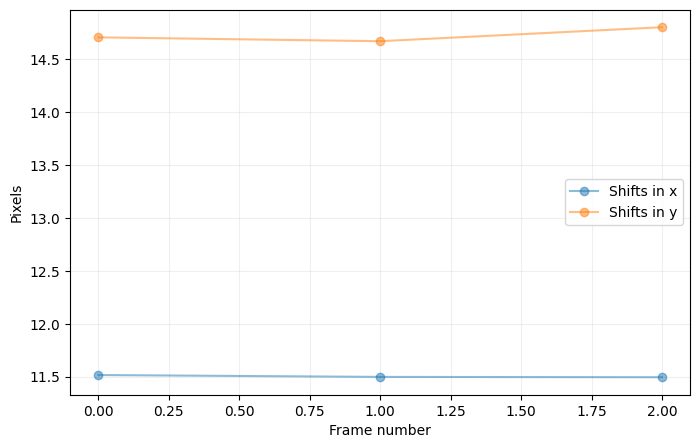

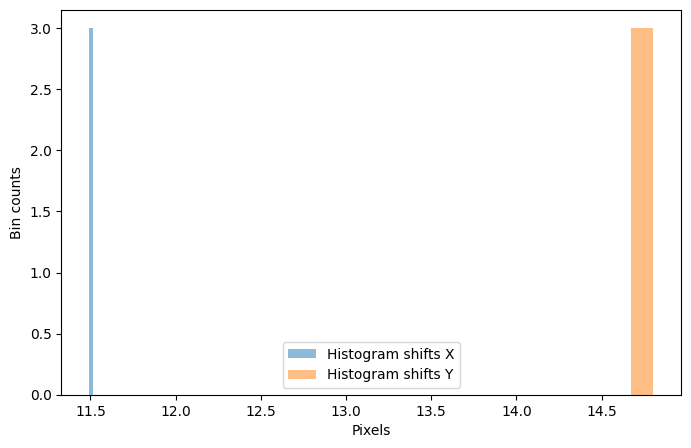

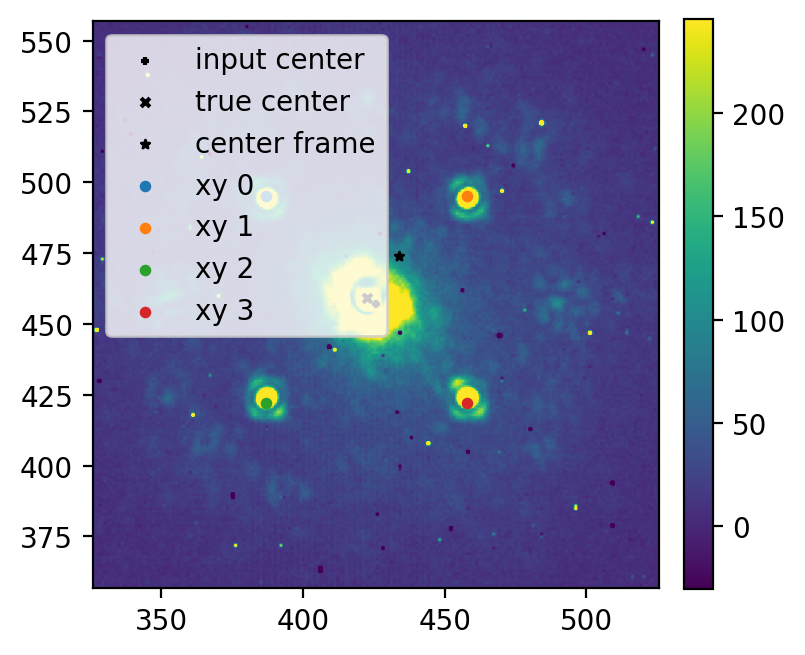

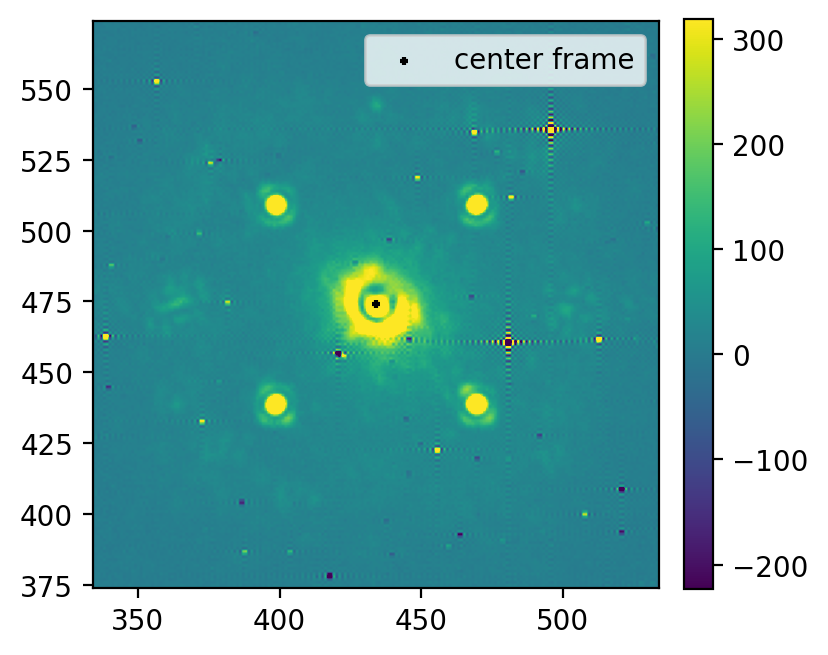

[(387, 495), (458, 495), (387, 422), (458, 422)]


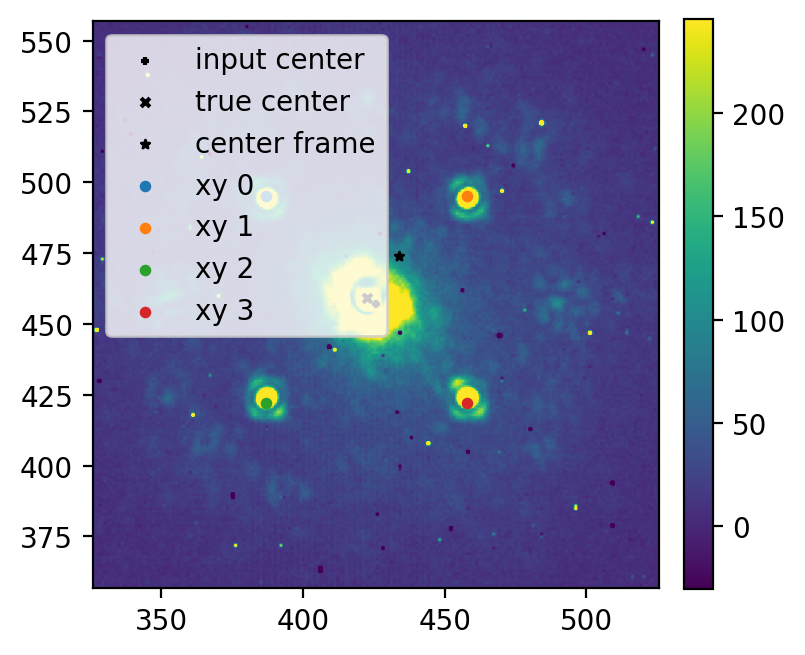

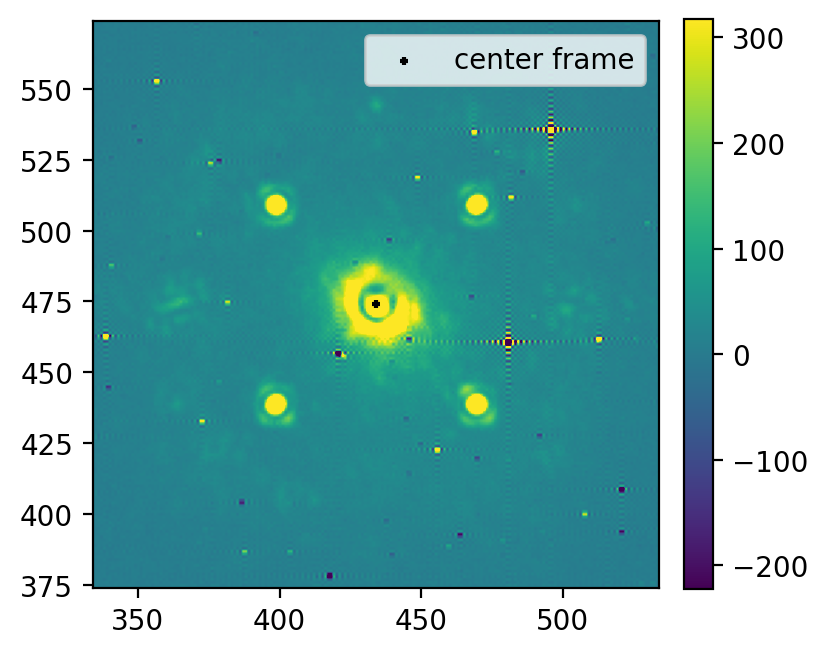

In [35]:
#res = get_center_cube(all_center_right[0], center = [440,480], sat_spots = np.array([[390, 495], [465,495], [390, 420], [465, 420]]))
#res = get_center_frame(all_center_right[0], center = [440,480], sat_spots = np.array([[390, 495], [465,495], [390, 420], [465, 420]]))

res = get_center_cube(all_center_right[0], sat_spots = centers)
res = get_center_frame(all_center_right[0], sat_spots = centers)

[(395.6986210470418, 486.9522439410928), (455.6986210470418, 486.9522439410928), (395.6986210470418, 426.9522439410928), (455.6986210470418, 426.9522439410928)]


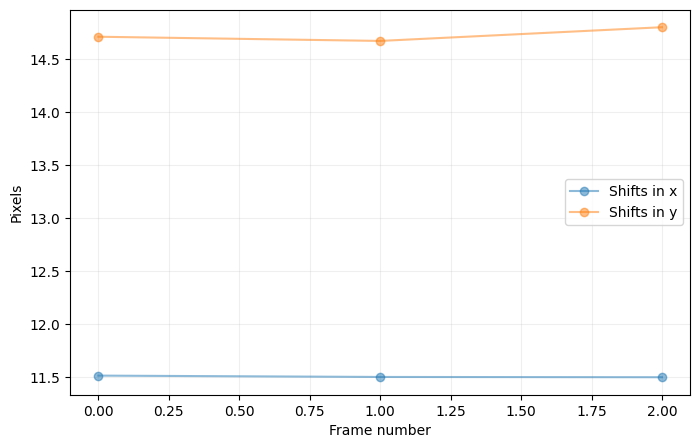

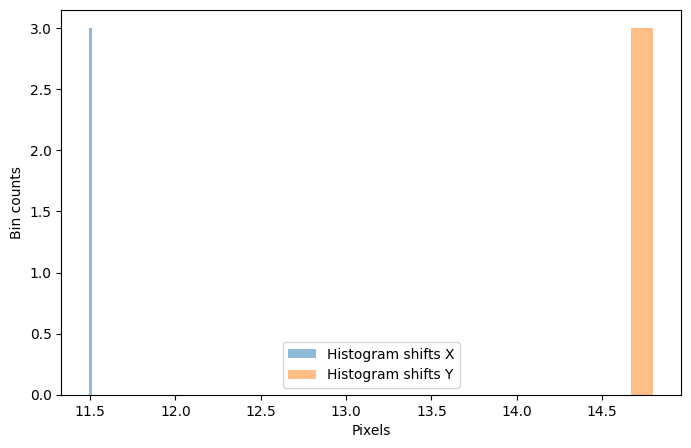

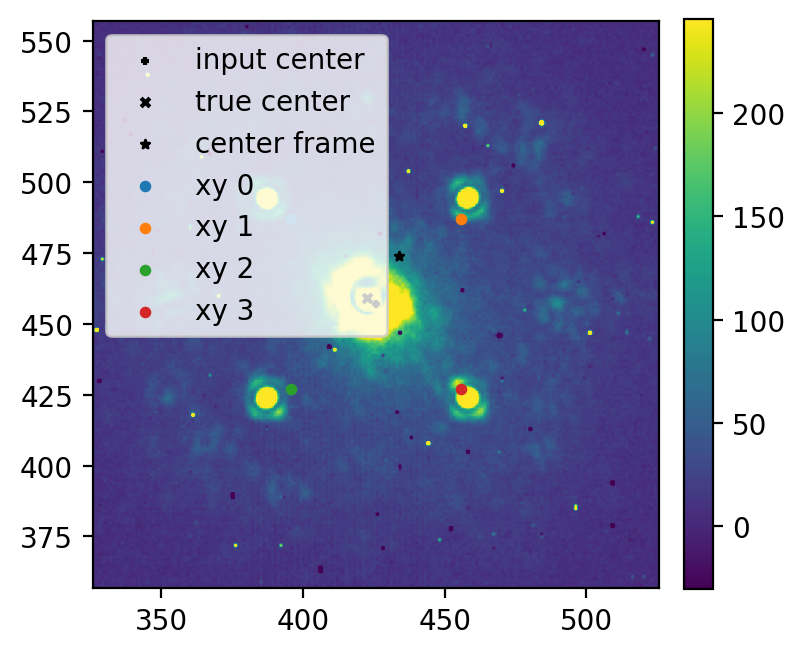

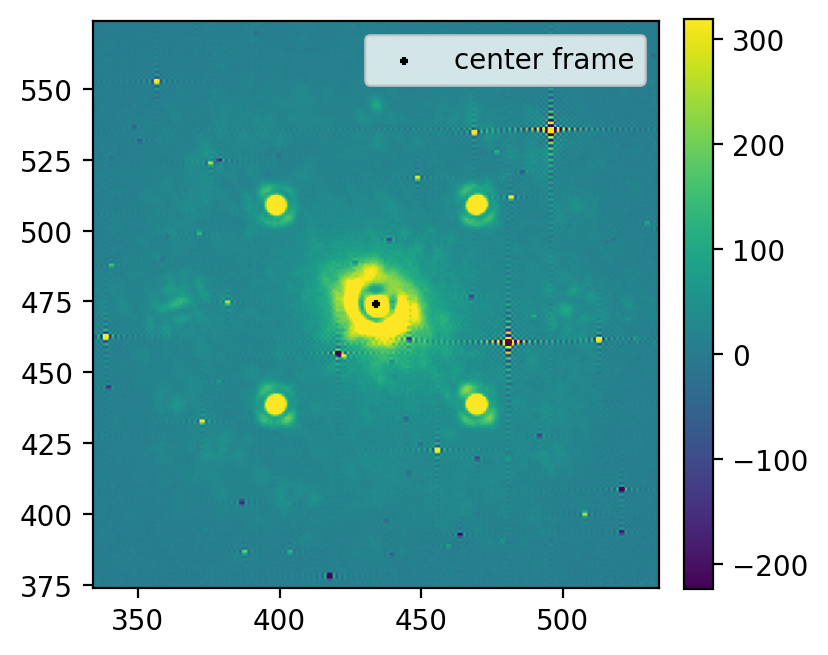

In [36]:
res = get_center_cube(all_center_right[0])
#res = get_center_frame(all_center_right[0])

In [ ]:
res[0].shape 

(3, 989, 908)

/home/pasteimle/code/ispy_env_3.8/lib/python3.8/site-packages/numpy/core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


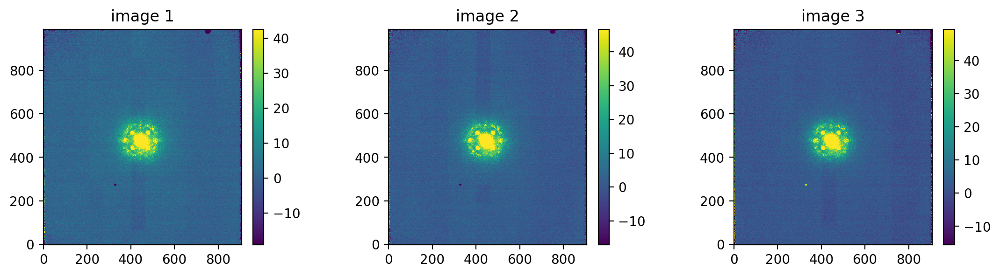

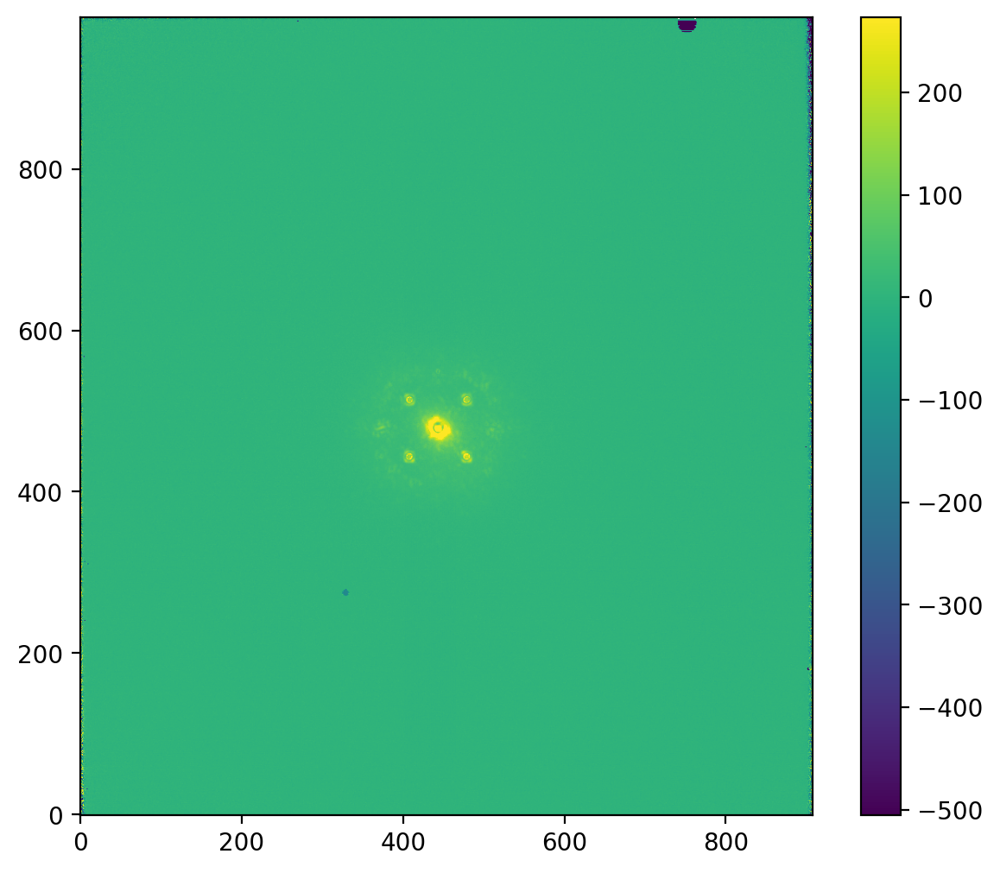

In [179]:
data = np.nan_to_num(fits.getdata(all_center_right[0]))

show_img([data[0],data[1], data[2]])
show_img(np.nanmedian(data, axis = 0), maxper = 99.9, minper = 0.1)

/home/pasteimle/code/ispy_env_3.8/lib/python3.8/site-packages/numpy/core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/home/pasteimle/code/ispy_env_3.8/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1556: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


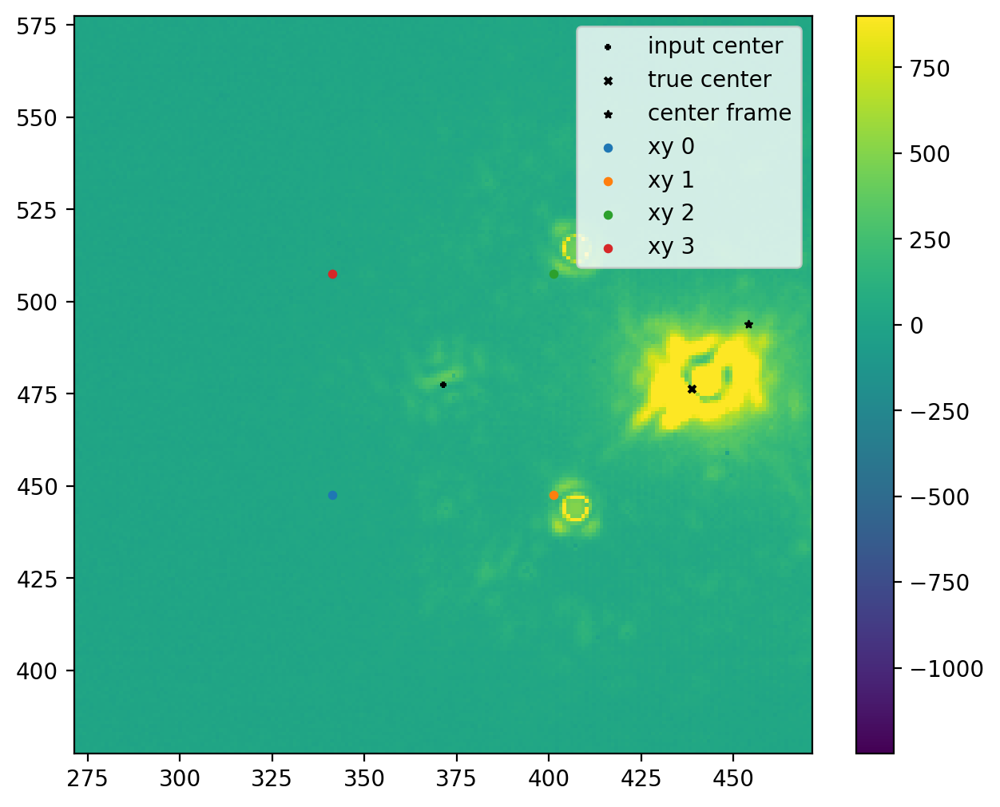

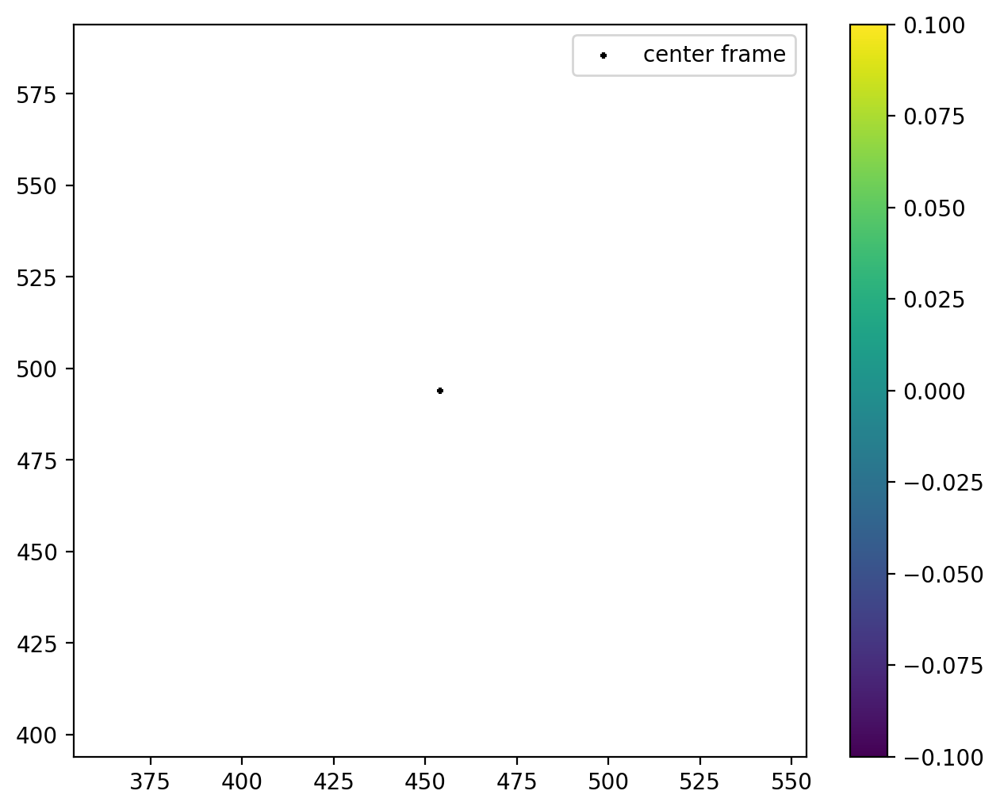

In [ ]:
def get_center_radon(file, center = None, sat_spots = None):

    data = np.nan_to_num(fits.getdata(file))
    image = np.nansum(data, axis=0)


    # try to find the center using centroid_1dg
    if center is None:
        center = centroid_1dg(image)

    #then roll the center there
    cy, cx = frame_center(image)
    # shifted_data = np.roll(data, int(cy - center[1]), axis=1)
    # shifted_data = np.roll(shifted_data, int(cx - center[0]), axis=2)

    # and try to use the now centered image with the sattelite spots
    if sat_spots is None:
        sat_spots = np.array([ [-30, -30], [30, -30], [30,30], [-30, 30]]) + center


    #foramt satspots.

    sat_spots_input = [(f[0], f[1]) for f in sat_spots]

    true_center = cube_recenter_radon(data, cropsize=121, hsize_ini=1.5, step_ini=0.1, mask_center=20, 
                                    nproc=None, satspots_cfg=None, full_output=False, verbose=True, n_iter=2,
                                    tol=0.05, plot=True, debug=True)


    # the unshifted image 
    show_img(image, minper=0.1, maxper=99.9, xlim=[center[0]-100,center[0]+100], ylim=[center[1]-100,center[1]+100])
    plt.scatter(center[0], center[1], color='black', s=10, label='input center', marker = '+')
    plt.scatter(true_center[1], true_center[0], color='black', s=10, label='true center', marker = 'x')
    plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '*')

    for j, xy in enumerate(sat_spots):
        plt.scatter(xy[0], xy[1], color=f'C{j}', s=10, label=f'xy {j}')
    plt.legend()


    # the shifted image with centers
    # show_img(shifted_image, minper=0.1, maxper=99.9, xlim=[cx-100,cx+100], ylim=[cy-100,cy+100])
    # plt.scatter(cx, cy, color='black', s=10, label='center frame', marker = '+')

    # plt.legend()


    return

res = get_center(all_center_right[1])

In [ ]:
from vip_hci.preproc import frame_center_radon
import matplotlib.pyplot as plt

for file in star_center_filepaths:
    data = fits.getdata(file)

    for image in data:


In [ ]:
data_corr = fits.getdata(main_dir.replace('raw_data','processed_data') + 'SCIENCE_BADPIX_CORR_SPHER.2023-07-24T08:08:19.549.fits')[0]
data = fits.getdata(main_dir + 'SCIENCE_SPHER.2023-07-24T08:08:19.549.fits')[0]

show_img([data_corr[:,:1000], data[:,:1000]], size = 2)

In [ ]:
data_corr = fits.getdata(main_dir.replace('raw_data','processed_data') + 'MASTER_FLAT.fits')
show_img(data_corr)

In [ ]:
data = fits.getdata(star_center_filepaths[0].replace('STAR_CENTER', 'STAR_FLAT_CORR_CENTER').replace('raw', 'processed'))


data.shape

In [ ]:
from vip_hci.preproc import cube_fix_badpix_isolated
from vip_hci.preproc import frame_center_radon

cube_sigcorr, bpm_mask = cube_fix_badpix_isolated(data, sigma_clip=5, num_neig=9, size=9, 
                                                frame_by_frame=False, mad=True, verbose=True, 
                                                full_output=True) 

In [ ]:
left_frame = cube_sigcorr[:, 35:, 40:948]
right_frame = cube_sigcorr[:, 35:, 1070:1978]

show_img([left_frame[0], right_frame[0]], size = 2, maxper=99.9, minper=0.1)

In [ ]:
from photutils.centroids import centroid_1dg, centroid_quadratic
from vip_hci.var import frame_center

cy, cx = frame_center(left_frame[0])

xy = centroid_1dg(left_frame[0])

%matplotlib inline
show_img(left_frame[0], maxper=99.9, minper=0.1, xlim=(xy[0]-50, xy[0]+50), ylim=(xy[1]-50, xy[1]+50), size = 2)
plt.scatter(xy[0], xy[1], color='red', s=10)
plt.scatter(cx, cy, marker='x', color='red', s=10)

for i, (x,y) in enumerate([(410, 520), (410, 455), (475,455), (475,520)]):
    plt.scatter(x, y, s=10, c='C{}'.format(i), label='{}'.format(i))

plt.legend()


print('frame_center', cy, cx)   
print('centroid_1dg', xy[1], xy[0])
print(cy - xy[1], cx - xy[0])


shifted_image = np.roll(left_frame, int(cy - xy[1]), axis=1)
shifted_image = np.roll(shifted_image, int(cx - xy[0]), axis=2)

show_img(shifted_image[0], maxper=99.9, minper=0.1, xlim=(cx-50, cx+50), ylim=(cy-50, cy+50), size = 2)
plt.scatter(cx, cy, marker='x', color='red', s=10)

In [ ]:
xys = []
for i in range(3):
    opt_y, opt_x = frame_center_radon(shifted_image[i], cropsize=121, hsize_ini=1.5, step_ini=0.1, mask_center=20, 
                                    nproc=None, satspots_cfg=None, full_output=False, verbose=True, n_iter=2,
                                    tol=0.05, plot=True, debug=True)
    xys.append((opt_x, opt_y))

In [ ]:
xys

In [ ]:
from vip_hci.preproc import cube_recenter_satspots, frame_center_satspots


xy = [(420, 530), (420, 465), (485,465), (485,530)]

for i in range(3):
    res = frame_center_satspots(right_frame[i], xy=xy, subi_size=221, verbose=False, debug=True)
    print(res)

In [ ]:
med_sh_y = np.median(shift_y)
med_sh_x = np.median(shift_x)
print("Median shifts (xy):", med_sh_x, med_sh_y)

In [ ]:
for i in range(3):
    show_img(left_frame[i], maxper=99.9, minper=0.1, xlim=(xy[0]-50, xy[0]+50), ylim=(xy[1]-50, xy[1]+50), size = 2)

In [ ]:
from astropy.io import fits
fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/MASTER_FLAT.fits')

In [ ]:
show_img(fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/STAR_CENTER_LEFT_SPHER.2023-07-24T09:03:57.589.fits')[0])

In [ ]:
import os 
os.listdir('/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data')
os.path.getsize('/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data/MASTER_FLAT.fits')

In [ ]:
8490240/1000/1000